# 04 — Queue-model sensitivity

Differences across models are estimates under explicit rules, not observed queue positions. The session figure can be flat. The divergence figure is a constructed counterexample, not a market sample.

max fill-rate gap across models at fixed delay: 0.0


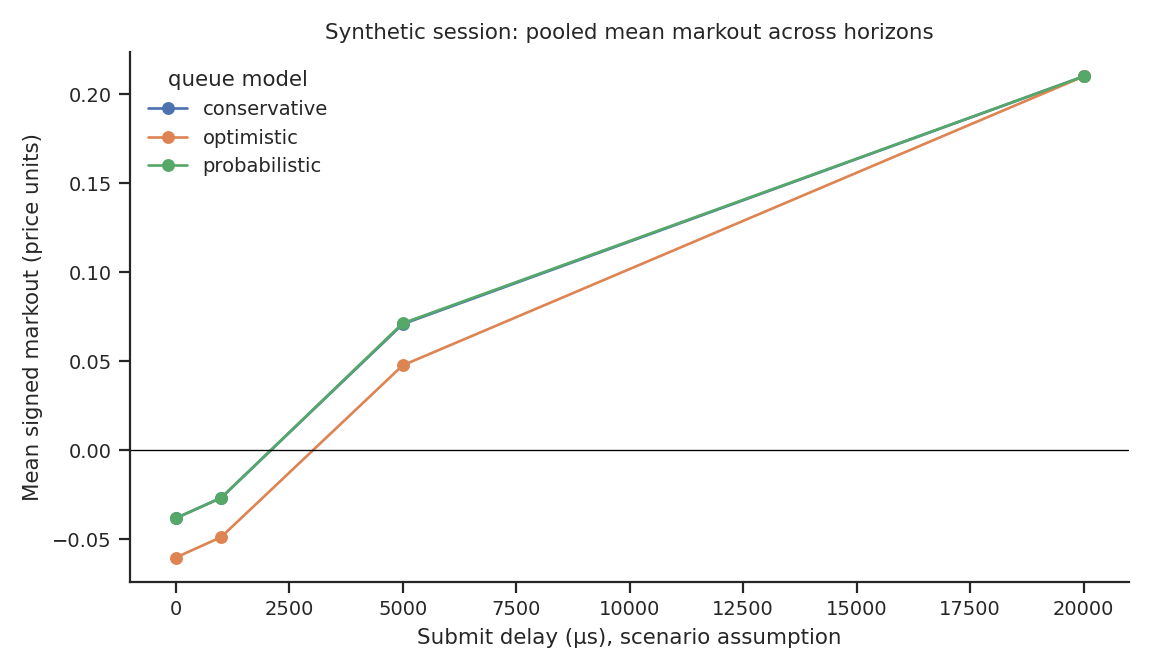

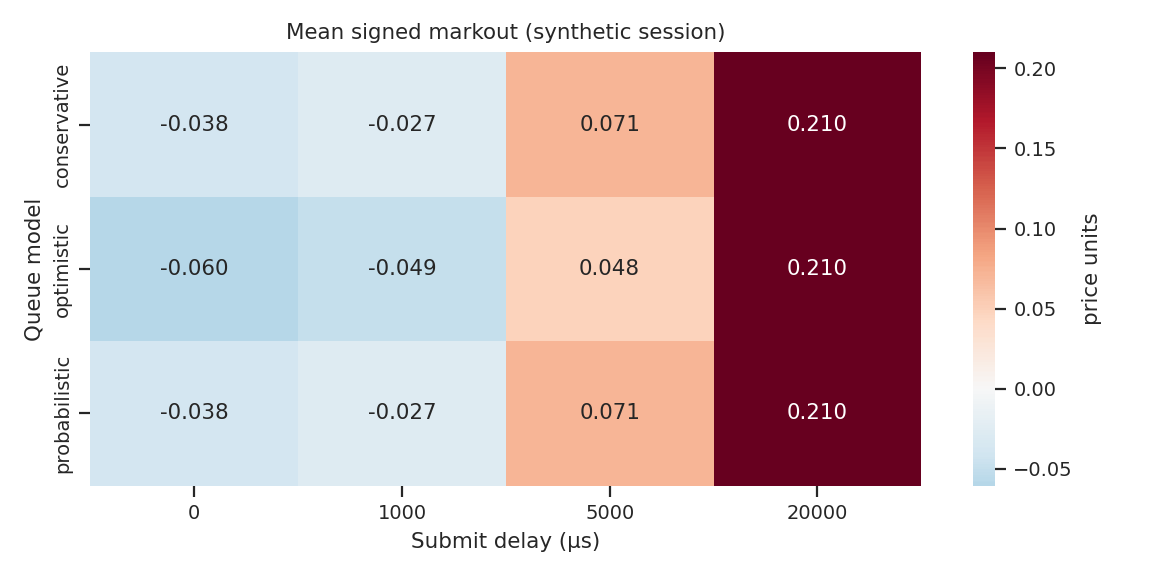

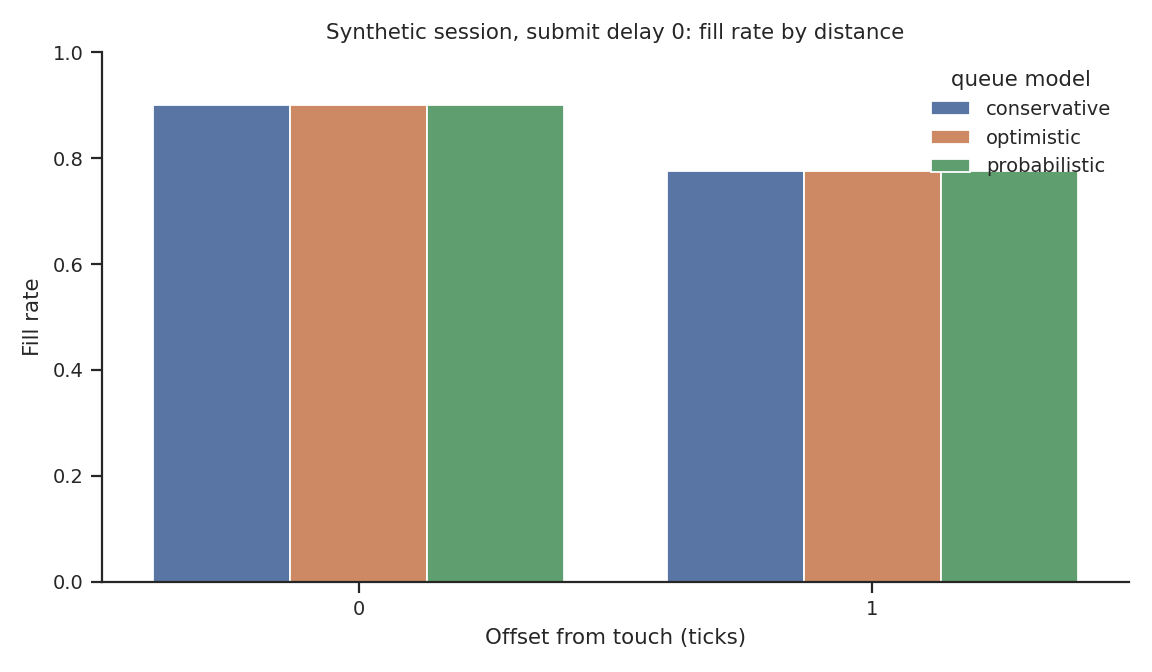

        model  filled_qty  status  n_fills
 conservative           0 working        0
probabilistic           0 working        0
   optimistic           1 working        1


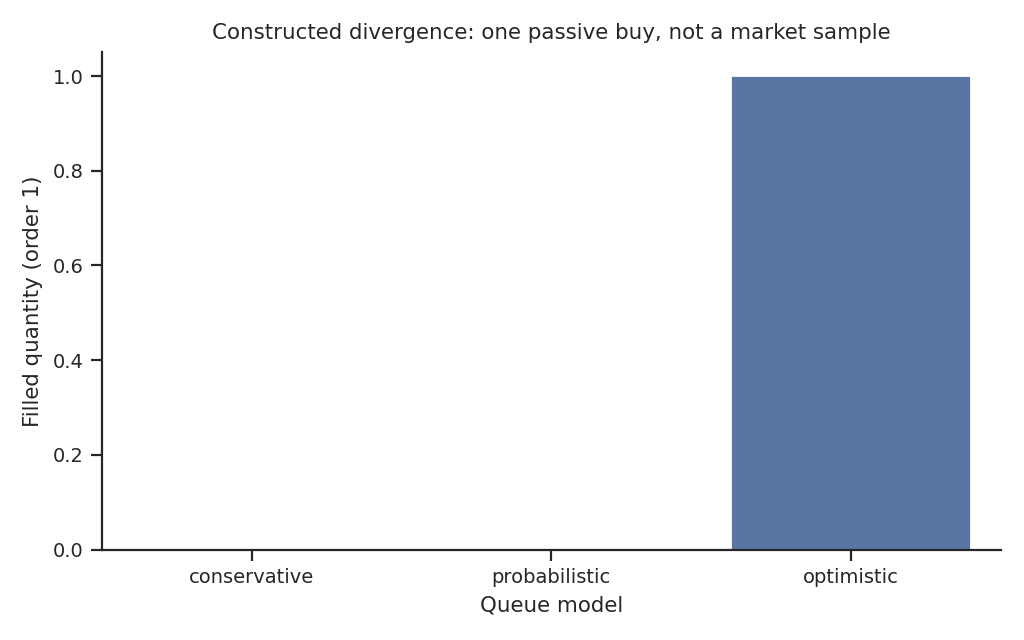

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "scripts" / "analysis.py").is_file():
    raise SystemExit("run this notebook from the repository root")
sys.path.insert(0, str(ROOT / "scripts"))
import analysis
from IPython.display import Image, display

def show(name):
    display(Image(filename=str(analysis.FIG / f"{name}.png")))

sens = analysis.sensitivity()
span = float(sens.groupby("submit_delay_us")["fill_rate"].agg(lambda s: s.max() - s.min()).max())
print("max fill-rate gap across models at fixed delay:", round(span, 6))
analysis.plot_markout(sens, analysis.FIG)
analysis.plot_markout_heatmap(sens, analysis.FIG)
analysis.plot_offset(analysis.executions(), analysis.FIG)
show("markout_by_latency")
show("markout_heatmap")
show("fill_rate_by_offset")
div = analysis.executions(analysis.DIVERGENCE)
print(div[["model", "filled_qty", "status", "n_fills"]].to_string(index=False))
analysis.plot_divergence(div, analysis.FIG)
show("divergence_filled_qty")
if div.loc[div["model"] == "optimistic", "filled_qty"].iloc[0] <= div.loc[div["model"] == "conservative", "filled_qty"].iloc[0]:
    raise RuntimeError("divergence fixture no longer separates optimistic from conservative")


Optimistic filled quantity should exceed conservative on this fixture. Probabilistic depends on the seed. A zero probabilistic fill is a draw, not a third deterministic bound.